# HR Analytics & Employee Attrition — Statistical Analysis

**Purpose:** test, with proper statistics, which employee characteristics are associated with attrition, and quantify how strong each association is. These results feed the annotations on Pages 2 and 3 of the Power BI dashboard.

**Input:** `data/cleaned/employees_clean.csv` (output of `sql/01_clean_data.sql`, 1,470 employees)

**Method overview**

| Step | Technique | Why |
|---|---|---|
| 1 | Data checks | Confirm the cleaned data is intact |
| 2 | Mean vs median | Income is skewed, so the median is the fairer centre |
| 3 | Chi-square + Cramér's V | Is a categorical factor associated with attrition, and how strongly? |
| 4 | Mann-Whitney U + rank-biserial r | Compare leavers and stayers on numeric variables without assuming normality |
| 5 | Correlation | Spearman correlation of numeric variables with attrition |
| 6 | Risk-factor stacking | Does attrition rise as risk factors accumulate? |
| 7 | Logistic regression | Which factors remain important after controlling for the others? |

> **Important:** every result here is an *association* in observational data. None of it proves that a factor *causes* attrition.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
CORAL, NAVY = '#F26464', '#273447'

df = pd.read_csv('../data/cleaned/employees_clean.csv')
print(df.shape)

(1470, 36)


## 1. Data checks

In [2]:
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate EmployeeNumber:', int(df['EmployeeNumber'].duplicated().sum()))
print('Attrition counts:'); print(df['Attrition'].value_counts())
print(f"\nOverall attrition rate: {df['AttritionFlag'].mean():.2%}")

Missing values: 0
Duplicate EmployeeNumber: 0
Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Overall attrition rate: 16.12%


The cleaned data is intact: 1,470 rows, no missing values, no duplicates. The attrition rate is **16.1%**, so the classes are imbalanced. Group rates should therefore be read *relative to* 16.1% rather than against 50%.

## 2. Mean vs median (is income skewed?)

In [3]:
summary = df.groupby('Attrition').agg(
    n=('EmployeeNumber', 'size'),
    mean_income=('MonthlyIncome', 'mean'),
    median_income=('MonthlyIncome', 'median'),
    mean_tenure=('YearsAtCompany', 'mean'),
    median_tenure=('YearsAtCompany', 'median'),
).round(1)
print(summary)
print(f"\nSkewness of MonthlyIncome: {df['MonthlyIncome'].skew():.2f}  (>1 = strongly right-skewed)")
print(f"Skewness of Age:           {df['Age'].skew():.2f}")

              n  mean_income  median_income  mean_tenure  median_tenure
Attrition                                                              
No         1233       6832.7         5204.0          7.4            6.0
Yes         237       4787.1         3202.0          5.1            3.0

Skewness of MonthlyIncome: 1.37  (>1 = strongly right-skewed)
Skewness of Age:           0.41


Income is strongly right-skewed, which is why the median (not the mean) is used when comparing leavers with stayers. Age is close to symmetric.

## 3. Chi-square tests: attrition vs categorical factors

In [4]:
def cramers_v(chi2, ct):
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

factors = ['OverTime', 'JobRole', 'MaritalStatus', 'BusinessTravel', 'EnvironmentSatisfaction',
           'JobSatisfaction', 'WorkLifeBalance', 'Department', 'EducationField', 'Gender']
rows = []
for col in factors:
    ct = pd.crosstab(df[col], df['Attrition'])
    chi2, p, dof, expected = chi2_contingency(ct)
    rows.append({'Factor': col, 'chi2': chi2, 'dof': dof, 'p_value': p,
                 'Cramers_V': cramers_v(chi2, ct),
                 'cells_expected_lt_5': f"{(expected < 5).sum()}/{expected.size}"})
chi_table = pd.DataFrame(rows).sort_values('Cramers_V', ascending=False).reset_index(drop=True)
chi_table['Significant (p<0.05)'] = chi_table['p_value'] < 0.05
display_tbl = chi_table.copy()
display_tbl['chi2'] = display_tbl['chi2'].round(2)
display_tbl['Cramers_V'] = display_tbl['Cramers_V'].round(3)
display_tbl['p_value'] = display_tbl['p_value'].map(lambda x: f"{x:.2e}")
print(display_tbl.to_string(index=False))

                 Factor  chi2  dof  p_value  Cramers_V cells_expected_lt_5  Significant (p<0.05)
               OverTime 87.56    1 8.16e-21      0.244                 0/4                  True
                JobRole 86.19    8 2.75e-15      0.242                0/18                  True
          MaritalStatus 46.16    2 9.46e-11      0.177                 0/6                  True
         BusinessTravel 24.18    2 5.61e-06      0.128                 0/6                  True
EnvironmentSatisfaction 22.50    3 5.12e-05      0.124                 0/8                  True
        JobSatisfaction 17.51    3 5.56e-04      0.109                 0/8                  True
        WorkLifeBalance 16.33    3 9.73e-04      0.105                 0/8                  True
         EducationField 16.02    5 6.77e-03      0.104                1/12                  True
             Department 10.80    2 4.53e-03      0.086                 0/6                  True
                 Gender  1.12 

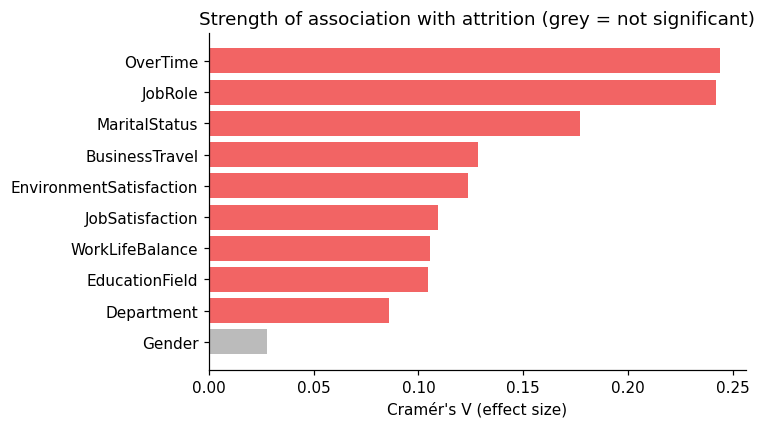

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
t = chi_table.sort_values('Cramers_V')
ax.barh(t['Factor'], t['Cramers_V'], color=[CORAL if s else '#BBBBBB' for s in t['Significant (p<0.05)']])
ax.set_xlabel("Cramér's V (effect size)")
ax.set_title('Strength of association with attrition (grey = not significant)')
plt.tight_layout(); plt.show()

**Reading the table.** The p-value says whether an association is unlikely to be chance; Cramér's V says *how strong* it is (about 0.1 small, 0.3 medium). **OverTime** and **JobRole** are the strongest, followed by **MaritalStatus**. **Gender** is the only factor with no significant association.

*Note on validity:* a few categories are small, so a minority of cells have expected counts below 5. The `cells_expected_lt_5` column shows how many; the share is below the usual 20% guideline, so the tests remain acceptable.

## 4. Mann-Whitney U: leavers vs stayers on numeric variables

In [6]:
numeric = ['MonthlyIncome', 'Age', 'TotalWorkingYears', 'YearsAtCompany',
           'YearsSinceLastPromotion', 'DistanceFromHome', 'PercentSalaryHike']
rows = []
for col in numeric:
    a = df.loc[df['Attrition'] == 'Yes', col]
    b = df.loc[df['Attrition'] == 'No', col]
    u, p = mannwhitneyu(a, b, alternative='two-sided')
    r = 1 - 2 * u / (len(a) * len(b))   # rank-biserial; positive = leavers tend to be LOWER
    rows.append({'Variable': col, 'median_leavers': a.median(), 'median_stayers': b.median(),
                 'mean_leavers': round(a.mean(), 2), 'mean_stayers': round(b.mean(), 2),
                 'p_value': f"{p:.2e}", 'rank_biserial_r': round(r, 3)})
mw = pd.DataFrame(rows)
print(mw.to_string(index=False))

               Variable  median_leavers  median_stayers  mean_leavers  mean_stayers  p_value  rank_biserial_r
          MonthlyIncome          3202.0          5204.0       4787.09       6832.74 2.95e-14            0.311
                    Age            32.0            36.0         33.61         37.56 5.30e-11            0.269
      TotalWorkingYears             7.0            10.0          8.24         11.86 2.40e-14            0.312
         YearsAtCompany             3.0             6.0          5.13          7.37 2.92e-13            0.298
YearsSinceLastPromotion             1.0             1.0          1.95          2.23 4.12e-02            0.080
       DistanceFromHome             9.0             7.0         10.63          8.92 2.39e-03           -0.124
      PercentSalaryHike            14.0            14.0         15.10         15.23 3.66e-01            0.037


**Why Mann-Whitney instead of a t-test?** Income and tenure are skewed, so a rank-based test is safer. The rank-biserial r is the effect size: a positive value means leavers tend to have *lower* values than stayers.

Leavers have lower income, are younger, and have less total experience and shorter tenure. **Years since last promotion** is statistically borderline but has a negligible effect, and leavers actually had slightly *fewer* years since promotion. The Phase 1 hypothesis that promotion delay drives attrition is therefore **not supported** by this data.

## 5. Correlation with attrition

TotalWorkingYears         -0.199
MonthlyIncome             -0.198
YearsAtCompany            -0.190
JobLevel                  -0.190
YearsInCurrentRole        -0.181
YearsWithCurrManager      -0.175
Age                       -0.171
JobInvolvement            -0.119
JobSatisfaction           -0.103
EnvironmentSatisfaction   -0.096
YearsSinceLastPromotion   -0.053
WorkLifeBalance           -0.052
TrainingTimesLastYear     -0.052
PercentSalaryHike         -0.024
NumCompaniesWorked         0.031
DistanceFromHome           0.079

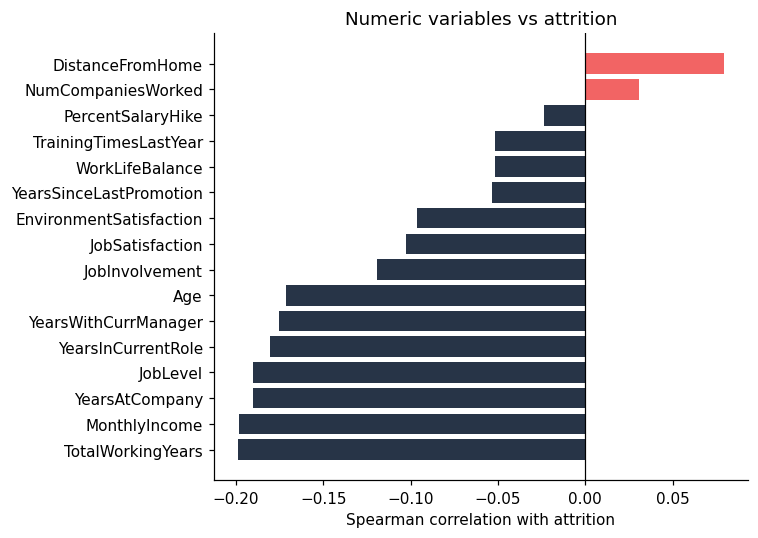

In [7]:
num_cols = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole',
            'YearsSinceLastPromotion', 'YearsWithCurrManager', 'DistanceFromHome', 'JobLevel',
            'NumCompaniesWorked', 'PercentSalaryHike', 'TrainingTimesLastYear',
            'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance', 'JobInvolvement']
corr = pd.Series({c: spearmanr(df[c], df['AttritionFlag'])[0] for c in num_cols}).sort_values()
print(corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr.index, corr.values, color=[CORAL if v > 0 else NAVY for v in corr.values])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Spearman correlation with attrition')
ax.set_title('Numeric variables vs attrition')
plt.tight_layout(); plt.show()

In [8]:
# Multicollinearity check that matters for the regression below
print('Spearman(MonthlyIncome, JobLevel):      %.2f' % spearmanr(df['MonthlyIncome'], df['JobLevel'])[0])
print('Spearman(MonthlyIncome, TotalWorkingYears): %.2f' % spearmanr(df['MonthlyIncome'], df['TotalWorkingYears'])[0])
print('Spearman(YearsAtCompany, YearsInCurrentRole): %.2f' % spearmanr(df['YearsAtCompany'], df['YearsInCurrentRole'])[0])

Spearman(MonthlyIncome, JobLevel):      0.92
Spearman(MonthlyIncome, TotalWorkingYears): 0.71
Spearman(YearsAtCompany, YearsInCurrentRole): 0.85


All correlations with attrition are **weak to moderate** (none above about 0.2 in absolute value), which is typical for human behaviour data. Income, job level and experience are very strongly correlated with each other, which matters for interpreting the regression in section 7.

## 6. Risk-factor stacking

            employees  left  rate
risk_count                       
0                 384    24   6.2
1                 532    37   7.0
2                 346    75  21.7
3                 164    67  40.9
4                  36    27  75.0
5                   8     7  87.5

            employees  left  rate
risk_level                       
Low (0-1)         916    61   6.7
Medium (2)        346    75  21.7
High (3+)         208   101  48.6


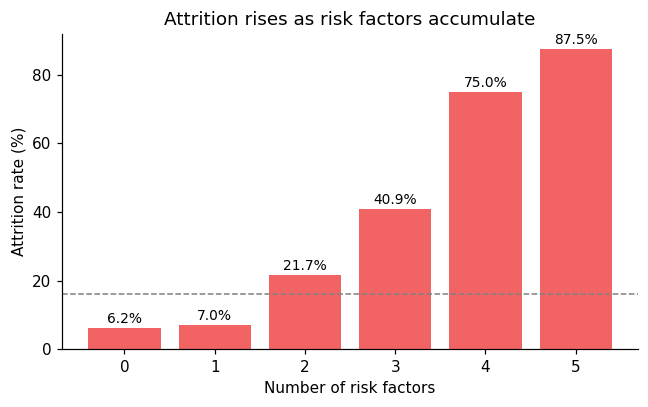

In [9]:
df['risk_count'] = (
    (df['OverTime'] == 'Yes').astype(int)
    + (df['MaritalStatus'] == 'Single').astype(int)
    + (df['MonthlyIncome'] < 3000).astype(int)
    + (df['YearsAtCompany'] <= 2).astype(int)
    + (df['BusinessTravel'] == 'Travel_Frequently').astype(int)
)
risk = df.groupby('risk_count')['AttritionFlag'].agg(employees='size', left='sum', rate='mean')
risk['rate'] = (risk['rate'] * 100).round(1)
print(risk)

df['risk_level'] = pd.cut(df['risk_count'], [-1, 1, 2, 5], labels=['Low (0-1)', 'Medium (2)', 'High (3+)'])
lvl = df.groupby('risk_level', observed=True)['AttritionFlag'].agg(employees='size', left='sum', rate='mean')
lvl['rate'] = (lvl['rate'] * 100).round(1)
print(); print(lvl)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(risk.index.astype(str), risk['rate'], color=CORAL)
for i, v in enumerate(risk['rate']): ax.text(i, v + 1.5, f"{v}%", ha='center', fontsize=9)
ax.axhline(df['AttritionFlag'].mean() * 100, ls='--', color='grey', lw=1)
ax.set_xlabel('Number of risk factors'); ax.set_ylabel('Attrition rate (%)')
ax.set_title('Attrition rises as risk factors accumulate')
plt.tight_layout(); plt.show()

Attrition climbs steadily from about 6% (0 risk factors) to over 40% (3 factors). The groups with 4 and 5 factors are small (36 and 8 employees), so their rates are indicative only.

**Caveat:** these five factors were chosen *after* looking at this same data, so the rates describe patterns in this dataset; they are not an out-of-sample prediction.

## 7. Logistic regression: which factors matter after controlling for the others?

In [10]:
y = df['AttritionFlag']
X = pd.DataFrame({
    'Overtime (Yes vs No)': (df['OverTime'] == 'Yes').astype(int),
    'Single (vs married/divorced)': (df['MaritalStatus'] == 'Single').astype(int),
    'Frequent business travel': (df['BusinessTravel'] == 'Travel_Frequently').astype(int),
    'Monthly income (per +$1,000)': df['MonthlyIncome'] / 1000,
    'Years at company (per +1 yr)': df['YearsAtCompany'],
    'Age (per +1 yr)': df['Age'],
    'Job satisfaction (per +1 level)': df['JobSatisfaction'],
    'Work-life balance (per +1 level)': df['WorkLifeBalance'],
    'Environment satisfaction (per +1 level)': df['EnvironmentSatisfaction'],
    'Distance from home (per +1 unit)': df['DistanceFromHome'],
    'Job level (per +1 level)': df['JobLevel'],
})
model = sm.Logit(y, sm.add_constant(X)).fit(disp=0)
ci = model.conf_int()
orx = pd.DataFrame({'odds_ratio': np.exp(model.params), 'ci_low': np.exp(ci[0]),
                    'ci_high': np.exp(ci[1]), 'p_value': model.pvalues}).drop('const')
orx = orx.sort_values('odds_ratio', ascending=False)
print(orx.round(3).to_string())
print(f"\nn = {len(y)}   pseudo-R2 = {model.prsquared:.3f}   in-sample AUC = {roc_auc_score(y, model.predict(sm.add_constant(X))):.3f}")

                                         odds_ratio  ci_low  ci_high  p_value
Overtime (Yes vs No)                          4.982   3.602    6.892    0.000
Single (vs married/divorced)                  2.706   1.966    3.725    0.000
Frequent business travel                      2.221   1.547    3.189    0.000
Distance from home (per +1 unit)              1.034   1.014    1.053    0.001
Monthly income (per +$1,000)                  0.974   0.866    1.095    0.657
Age (per +1 yr)                               0.970   0.950    0.990    0.003
Years at company (per +1 yr)                  0.964   0.928    1.001    0.056
Job level (per +1 level)                      0.774   0.480    1.247    0.292
Work-life balance (per +1 level)              0.760   0.611    0.944    0.013
Job satisfaction (per +1 level)               0.703   0.611    0.809    0.000
Environment satisfaction (per +1 level)       0.702   0.608    0.811    0.000

n = 1470   pseudo-R2 = 0.205   in-sample AUC = 0.804


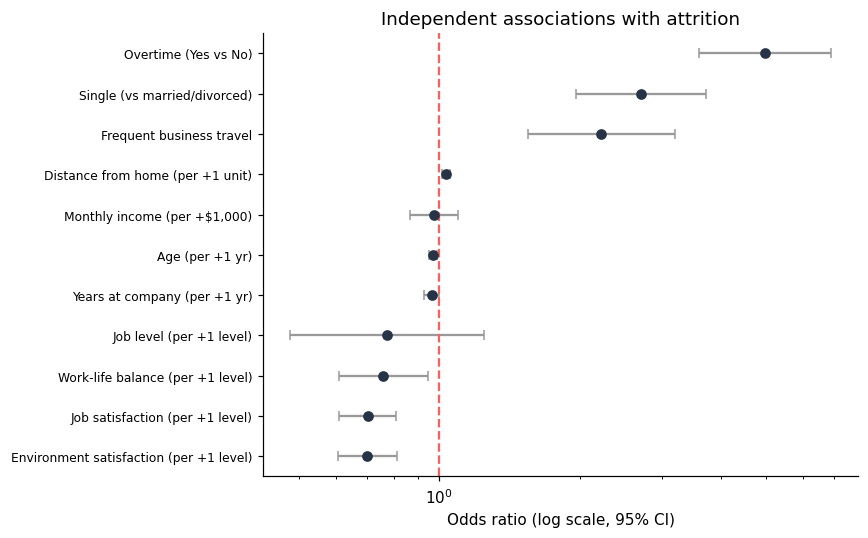

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
t = orx.iloc[::-1]
ax.errorbar(t['odds_ratio'], range(len(t)),
            xerr=[t['odds_ratio'] - t['ci_low'], t['ci_high'] - t['odds_ratio']],
            fmt='o', color=NAVY, ecolor='#999999', capsize=3)
ax.axvline(1, color=CORAL, ls='--')
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('Odds ratio (log scale, 95% CI)')
ax.set_title('Independent associations with attrition')
plt.tight_layout(); plt.show()

**How to read it.** An odds ratio above 1 raises the *odds* of leaving; below 1 lowers them. Holding the other factors fixed, overtime has an odds ratio of roughly 5, being single about 2.7 and frequent travel about 2.2. Each extra level of job or environment satisfaction lowers the odds by roughly 30%.

**Income is the notable exception.** It looked like a driver in the simple comparisons (section 4), but once job level, age and tenure are in the model its independent effect is not significant. Income, job level and experience move together (section 5), so the model cannot separate their effects. This is a correlated-predictors issue, *not* evidence that pay is irrelevant.

The model is for **explanation, not prediction**: the AUC is in-sample and no hold-out test was used.

## 8. Conclusions and limitations

**Conclusions**
1. **Overtime** is the strongest and most actionable factor: roughly 3× higher attrition in a simple comparison and about 5× higher odds after controlling for other factors.
2. **Job role, marital status and business travel** are the next strongest categorical associations.
3. Risk **stacks**: employees with three or more risk factors leave at several times the company rate.
4. **Promotion delay** and **gender** show no meaningful association in this data.
5. **Pay** appears important on its own but is entangled with job level, age and tenure.

**Limitations**
- Observational data: associations only, no causal claims.
- The IBM HR dataset is a fictional, publicly available dataset, so findings illustrate the method rather than describe a real company.
- No date field, so true attrition trends over time cannot be analysed.
- Multiple tests were run; the key results are far below the 0.05 threshold, but borderline p-values should be treated with caution.
- The regression is in-sample and has not been validated on held-out data.